# Data Exploration

In [1]:
from google.colab import files

uploaded = files.upload()

Saving gtsrb.zip to gtsrb.zip


In [2]:
import zipfile
from pathlib import Path

zip_path = "/content/gtsrb.zip"
extract_dir = Path("/content/gtsrb")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extracted successfully!")

Extracted successfully!


In [3]:
from pathlib import Path

for p in Path("/content/gtsrb").rglob("Train.csv"):
    print("Train CSV:", p)

for p in Path("/content/gtsrb").rglob("Test.csv"):
    print("Test CSV:", p)

Train CSV: /content/gtsrb/gtsrb/Train.csv
Test CSV: /content/gtsrb/gtsrb/Test.csv


In [4]:
import torch
import torchvision
from torchvision.datasets import GTSRB

import numpy  as np
import matplotlib.pyplot as plt

from collections import Counter
from pathlib import Path

In [7]:

import pandas as pd
from pathlib import Path

data_dir = Path("/content/gtsrb/gtsrb")

train_csv = pd.read_csv(data_dir / "Train.csv")
test_csv = pd.read_csv(data_dir / "Test.csv")

print("Train shape:", train_csv.shape)
print("Test shape:", test_csv.shape)

display(train_csv.head())


Train shape: (39209, 8)
Test shape: (12630, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [8]:
print(train_csv["ClassId"].nunique())
print(train_csv["ClassId"].value_counts().sort_index())

43
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64


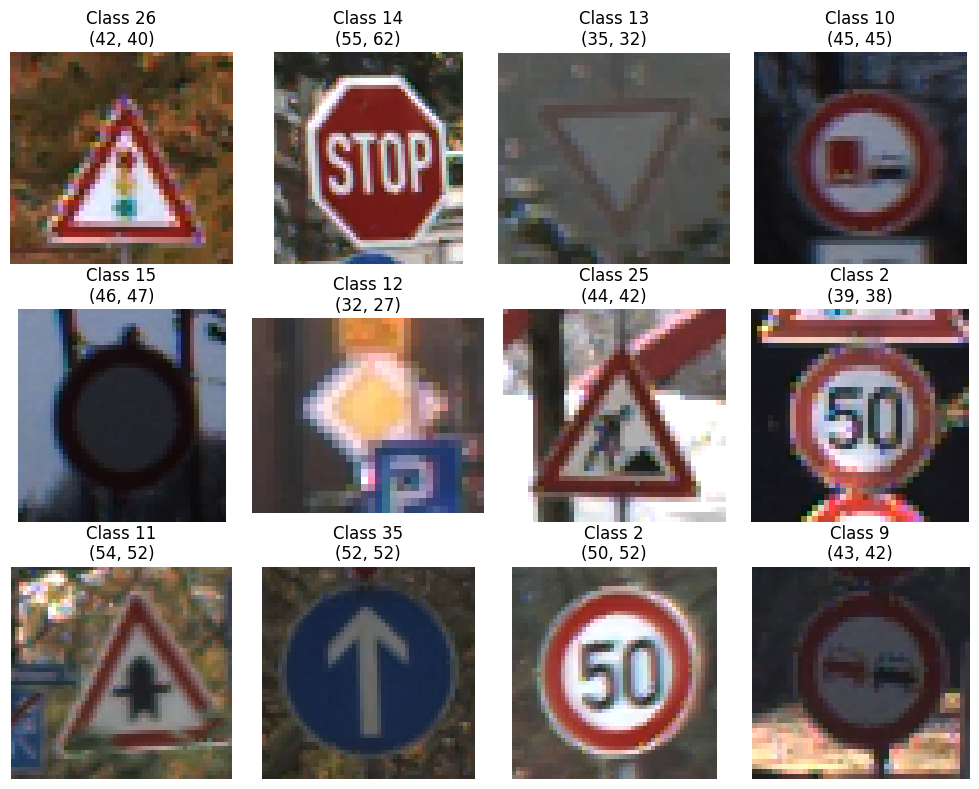

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

# Randomly choose 12 training examples
samples = train_csv.sample(12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):

    img_path = data_dir / row["Path"]
    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(f"Class {row['ClassId']}\n{img.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:

import pandas as pd
from pathlib import Path

data_dir = Path("/content/gtsrb/gtsrb")

train_csv = pd.read_csv(data_dir / "Train.csv")
test_csv = pd.read_csv(data_dir / "Test.csv")

all_df = pd.concat([train_csv, test_csv], ignore_index=True)

print("Total images:", len(all_df))
print("Number of classes:", all_df["ClassId"].nunique())


Total images: 51839
Number of classes: 43


## Test Train Split

In [11]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    all_df,
    test_size=0.30,
    random_state=42,
    stratify=all_df["ClassId"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["ClassId"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 36287
Validation: 7776
Test: 7776


In [12]:
n = len(all_df)

print(f"Train: {len(train_df)/n:.2%}")
print(f"Validation: {len(val_df)/n:.2%}")
print(f"Test: {len(test_df)/n:.2%}")

Train: 70.00%
Validation: 15.00%
Test: 15.00%


## Resizing and Padding

In [13]:
from PIL import Image, ImageOps
from torchvision import transforms

class ResizeAndPad:
    def __init__(self, size = (32,32)):
        self.size = size
    def __call__(self, image):
        return ImageOps.pad(
            image,
            self.size,
            method = Image.Resampling.BILINEAR,
            color = (0,0,0),
            centering = (0.5, 0.5, 0.5)
        )

In [14]:
from torch.utils.data import Dataset
class GTSRBDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = self.root_dir / row["Path"]

        image = Image.open(img_path).convert("RGB")
        label = int(row["ClassId"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [15]:
transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor()
])


In [16]:
train_dataset = GTSRBDataset(
    train_df,
    data_dir,
    transform=transform
)

val_dataset = GTSRBDataset(
    val_df,
    data_dir,
    transform=transform
)

test_dataset = GTSRBDataset(
    test_df,
    data_dir,
    transform=transform
)

In [17]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

36287
7776
7776


In [18]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [19]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([64, 3, 32, 32])
Labels: torch.Size([64])


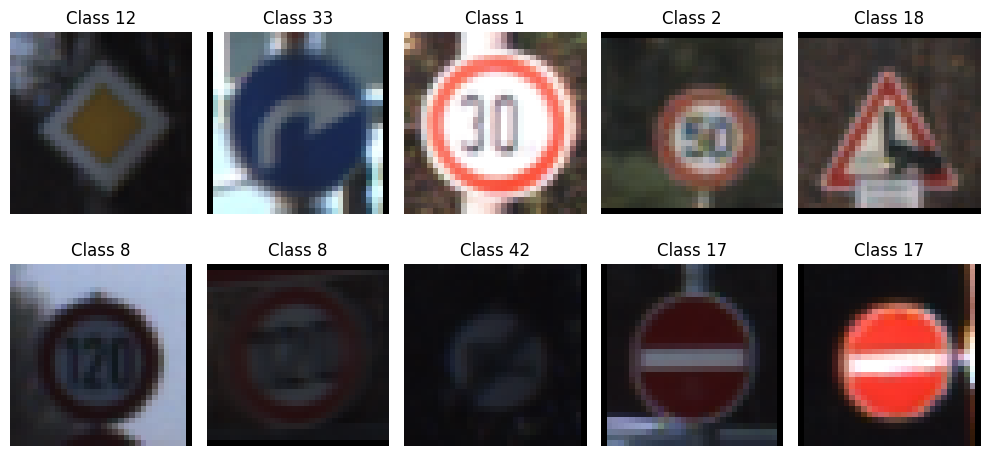

In [20]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.ravel()):
    img = images[i].permute(1, 2, 0)

    ax.imshow(img)
    ax.set_title(f"Class {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Normalizing the Data

In [21]:
import torch

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
num_pixels = 0

for images, _ in train_loader:
    # images shape: [B, C, H, W]
    channel_sum += images.sum(dim=[0, 2, 3]) #summing accross all 64 images, channel by channel
    channel_sum_sq += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / num_pixels
std = torch.sqrt(channel_sum_sq / num_pixels - mean ** 2)

print("Mean:", mean)
print("Std :", std)

Mean: tensor([0.3219, 0.2955, 0.3048])
Std : tensor([0.2742, 0.2621, 0.2689])


New Transform including the normalization

In [22]:
transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [23]:
train_dataset = GTSRBDataset(train_df, data_dir, transform = transform)
val_dataset = GTSRBDataset(val_df,data_dir, transform= transform)
test_dataset = GTSRBDataset(test_df, data_dir, transform = transform)


In [24]:
train_transform = transforms.Compose([
    ResizeAndPad((32, 32)),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [25]:
eval_transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [26]:
train_dataset = GTSRBDataset(
    train_df,
    data_dir,
    transform=train_transform
)

val_dataset = GTSRBDataset(
    val_df,
    data_dir,
    transform=eval_transform
)

test_dataset = GTSRBDataset(
    test_df,
    data_dir,
    transform=eval_transform
)

In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

## CNN Model A

In [ ]:
from torch import nn

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 43)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [ ]:
model_a = LeNet()
print(model_a)

In [ ]:
images, labels = next(iter(train_loader))

print("Input:", images.shape)

outputs = model_a(images)

print("Output:", outputs.shape)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

In [ ]:
model_a = model_a.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_a.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 20

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model_a.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Remove gradients from previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model_a(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Predictions
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total

    # -------------------------
    # Validation
    # -------------------------
    model_a.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_a(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = correct / total

    # Store results
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(7, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A: Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A: Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

In [ ]:
model_a.eval()

test_loss = 0.0
correct = 0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_a(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

cm = confusion_matrix(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print("Weighted Precision:", precision)
print("Weighted Recall:", recall)

In [ ]:
macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("Macro Precision:", macro_precision)
print("Macro Recall:", macro_recall)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Model A - Confusion Matrix")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
)

plt.figure(figsize=(12, 10))

plt.imshow(cm_norm, interpolation="nearest")
plt.title("Model A - Normalized Confusion Matrix")

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Proportion")

plt.tight_layout()
plt.show()

In [ ]:
cm_errors = cm_norm.copy()

# Remove correct predictions
import numpy as np
np.fill_diagonal(cm_errors, 0)

plt.figure(figsize=(12, 10))

plt.imshow(cm_errors, interpolation="nearest")
plt.title("Model A - Normalized Misclassifications Only")

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Misclassification proportion")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

cm_errors = cm_norm.copy()
np.fill_diagonal(cm_errors, 0)

# Find the 10 largest off-diagonal entries
flat_indices = np.argsort(cm_errors.ravel())[::-1]

print("Top confusion pairs:")
count = 0

for idx in flat_indices:
    true_class, predicted_class = np.unravel_index(idx, cm_errors.shape)
    value = cm_errors[true_class, predicted_class]

    if value == 0:
        break

    print(
        f"True {true_class:2d} → Predicted {predicted_class:2d}: "
        f"{value * 100:.2f}%"
    )

    count += 1
    if count == 10:
        break

## CNN Model A v2

Added another conv layer

In [ ]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            3, 16,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            16, 32,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            32, 64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 43)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

Training

In [ ]:
import torch
import torch.nn as nn
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

model_improved = ImprovedCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_improved.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_acc = 0.0
best_model_state = None

for epoch in range(num_epochs):

    # =====================================================
    # TRAINING
    # =====================================================
    model_improved.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model_improved(images)

        # Loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * images.size(0)

        # Predictions
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total


    # =====================================================
    # VALIDATION
    # =====================================================
    model_improved.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_improved(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = correct / total


    # =====================================================
    # STORE RESULTS
    # =====================================================
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)


    # Save the best model according to validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model_improved.state_dict())


    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Training and Validation Curves

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(7, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN - Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

Accuracy

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN - Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

Test Eval

In [ ]:
model_improved.eval()

test_loss = 0.0
correct = 0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_improved(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_accuracy = correct / total

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

weighted_precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

weighted_recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

print()

print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
)

plt.figure(figsize=(12, 10))

plt.imshow(cm_norm, interpolation="nearest")

plt.title("Improved CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Proportion")

plt.tight_layout()
plt.show()

In [ ]:
total_params = sum(
    p.numel()
    for p in model_improved.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

## Model B

##  ARCHITECTURE DEFINITION

In [28]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # Depthwise Conv (groups = in_channels)
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels, bias=False)
        self.bn1 = nn.BatchNorm2d(in_channels)
        # Pointwise Conv (1x1)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.act = nn.ReLU6(inplace=True)

    def forward(self, x):
        return self.act(self.bn2(self.pointwise(self.act(self.bn1(self.depthwise(x))))))

class ModelB_LightweightCNN(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU6(inplace=True)
        )
        self.block1 = DepthwiseSeparableConv(32, 64)
        self.pool1 = nn.MaxPool2d(2, 2)

        self.block2 = DepthwiseSeparableConv(64, 128)
        self.pool2 = nn.MaxPool2d(2, 2)

        self.block3 = DepthwiseSeparableConv(128, 128)
        self.pool3 = nn.MaxPool2d(2, 2)

        self.block4 = DepthwiseSeparableConv(128, 128)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.25)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.block1(x))
        x = self.pool2(self.block2(x))
        x = self.pool3(self.block3(x))
        x = self.block4(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_b = ModelB_LightweightCNN(num_classes=43).to(device)

print(f"Model B Trainable Parameters: {sum(p.numel() for p in model_b.parameters() if p.requires_grad):,}")



Model B Trainable Parameters: 54,251


## TRAINING LOOP (20 EPOCHS)

In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_b.parameters(), lr=0.001)
num_epochs = 20

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(num_epochs):
    # Training phase
    model_b.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_b(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total

    # Validation phase
    model_b.eval()
    val_loss_running, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_b(images)
            loss = criterion(outputs, labels)
            val_loss_running += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (preds == labels).sum().item()

    val_loss = val_loss_running / len(val_loader.dataset)
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")



Epoch 01/20 | Train Loss: 0.0428, Acc: 0.9869 | Val Loss: 0.0131, Acc: 0.9958
Epoch 02/20 | Train Loss: 0.0357, Acc: 0.9892 | Val Loss: 0.0151, Acc: 0.9946
Epoch 03/20 | Train Loss: 0.0365, Acc: 0.9886 | Val Loss: 0.0121, Acc: 0.9967
Epoch 04/20 | Train Loss: 0.0322, Acc: 0.9902 | Val Loss: 0.0094, Acc: 0.9970
Epoch 05/20 | Train Loss: 0.0249, Acc: 0.9924 | Val Loss: 0.0089, Acc: 0.9974
Epoch 06/20 | Train Loss: 0.0262, Acc: 0.9922 | Val Loss: 0.0142, Acc: 0.9950
Epoch 07/20 | Train Loss: 0.0262, Acc: 0.9917 | Val Loss: 0.0120, Acc: 0.9964
Epoch 08/20 | Train Loss: 0.0233, Acc: 0.9929 | Val Loss: 0.0131, Acc: 0.9960
Epoch 09/20 | Train Loss: 0.0214, Acc: 0.9937 | Val Loss: 0.0106, Acc: 0.9964
Epoch 10/20 | Train Loss: 0.0214, Acc: 0.9930 | Val Loss: 0.0080, Acc: 0.9969
Epoch 11/20 | Train Loss: 0.0194, Acc: 0.9940 | Val Loss: 0.0070, Acc: 0.9976
Epoch 12/20 | Train Loss: 0.0186, Acc: 0.9943 | Val Loss: 0.0093, Acc: 0.9967
Epoch 13/20 | Train Loss: 0.0181, Acc: 0.9939 | Val Loss: 0.0124

## PLOTS (LOSS & ACCURACY)

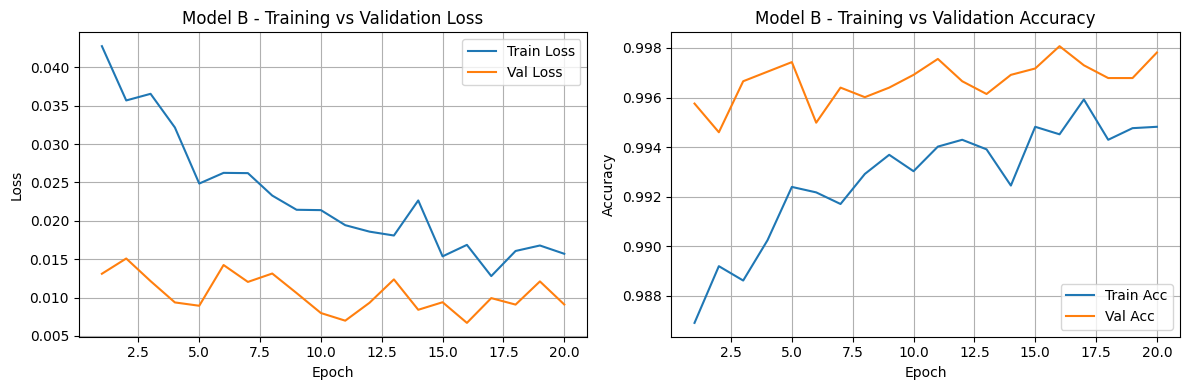

In [31]:
epochs = range(1, num_epochs + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, train_losses, label='Train Loss')
ax[0].plot(epochs, val_losses, label='Val Loss')
ax[0].set_title('Model B - Training vs Validation Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(epochs, train_accuracies, label='Train Acc')
ax[1].plot(epochs, val_accuracies, label='Val Acc')
ax[1].set_title('Model B - Training vs Validation Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()



## TEST SET EVALUATION & METRICS

In [32]:
model_b.eval()
test_loss, correct, total = 0.0, 0, 0
all_labels, all_preds = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_b(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

print(f"\nTest Loss: {test_loss/len(test_loader.dataset):.4f}")
print(f"Test Accuracy: {correct/total:.4%}")
print(f"Weighted Precision: {precision_score(all_labels, all_preds, average='weighted', zero_division=0):.4f}")
print(f"Weighted Recall:    {recall_score(all_labels, all_preds, average='weighted', zero_division=0):.4f}")
print(f"Weighted F1-Score:  {f1_score(all_labels, all_preds, average='weighted', zero_division=0):.4f}")
print(f"Macro Precision:    {precision_score(all_labels, all_preds, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:       {recall_score(all_labels, all_preds, average='macro', zero_division=0):.4f}")



Test Loss: 0.0082
Test Accuracy: 99.7171%
Weighted Precision: 0.9972
Weighted Recall:    0.9972
Weighted F1-Score:  0.9972
Macro Precision:    0.9960
Macro Recall:       0.9964


## CONFUSION MATRIX

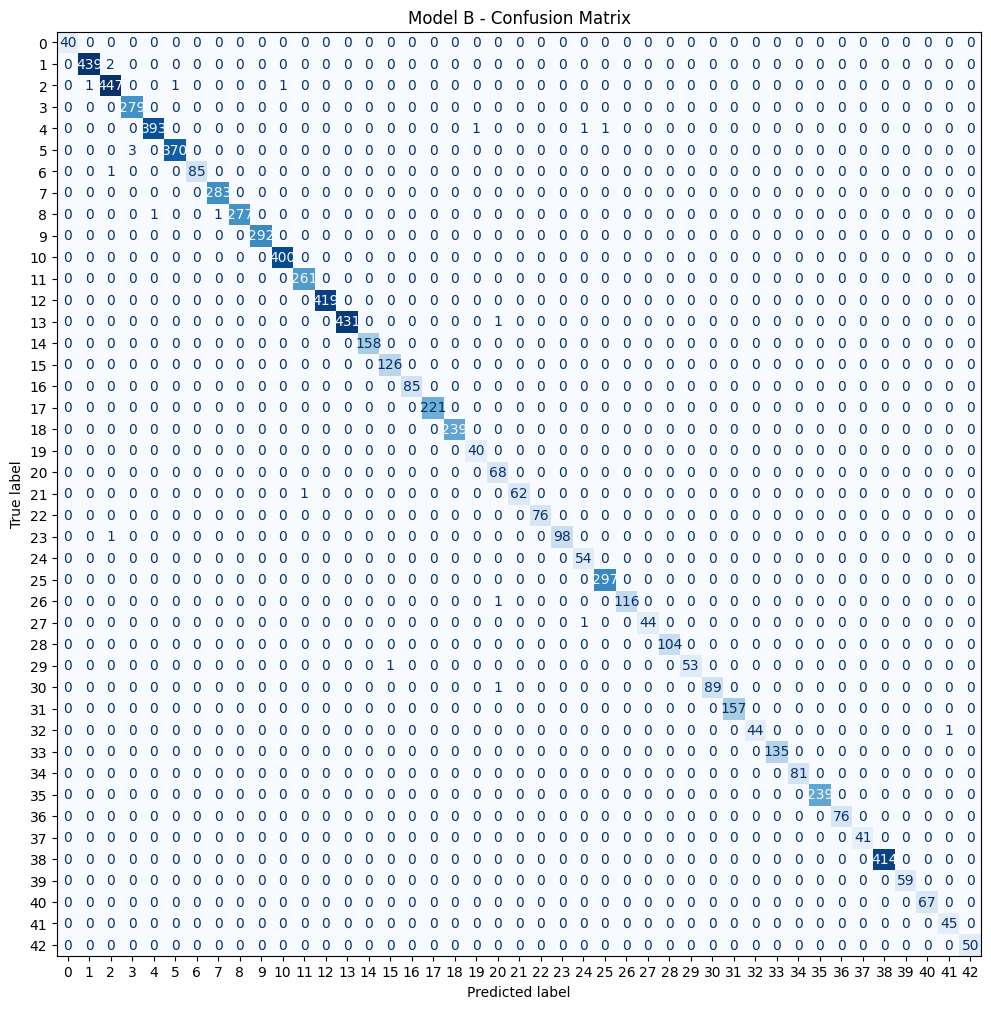

In [33]:
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(confusion_matrix(all_labels, all_preds)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Model B - Confusion Matrix")
plt.show()

## PARAMETER TABLE AND SIZE ON THE DISK

In [34]:
import os
total = 0
for name, p in model_b.named_parameters():
    print(f"{name:35s} {str(tuple(p.shape)):20s} {p.numel():>8,}")
    total += p.numel()
print("TOTAL trainable parameters:", f"{total:,}", "| under 100k:", total < 100_000)

torch.save(model_b.state_dict(), "model_b.pth")
print("Model size (KB):", os.path.getsize("model_b.pth") / 1024)

stem.0.weight                       (32, 3, 3, 3)             864
stem.1.weight                       (32,)                      32
stem.1.bias                         (32,)                      32
block1.depthwise.weight             (32, 1, 3, 3)             288
block1.bn1.weight                   (32,)                      32
block1.bn1.bias                     (32,)                      32
block1.pointwise.weight             (64, 32, 1, 1)          2,048
block1.bn2.weight                   (64,)                      64
block1.bn2.bias                     (64,)                      64
block2.depthwise.weight             (64, 1, 3, 3)             576
block2.bn1.weight                   (64,)                      64
block2.bn1.bias                     (64,)                      64
block2.pointwise.weight             (128, 64, 1, 1)         8,192
block2.bn2.weight                   (128,)                    128
block2.bn2.bias                     (128,)                    128
block3.dep

## MACs

In [39]:
import torch
import torch.nn as nn

def count_macs(model, input_size=(1, 3, 32, 32)):
    """Counts MACs of Conv2d and Linear layers for one input image.
    BatchNorm, activations and pooling are not counted (they are small)."""
    total = {"macs": 0}
    per_layer = []

    def conv_hook(module, inp, out):
        # MACs = output elements x (in_channels / groups) x kernel_h x kernel_w
        macs = out.numel() * (module.in_channels // module.groups) \
               * module.kernel_size[0] * module.kernel_size[1]
        total["macs"] += macs
        per_layer.append((module, macs))

    def fc_hook(module, inp, out):
        macs = module.in_features * module.out_features
        total["macs"] += macs
        per_layer.append((module, macs))

    hooks = []
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            hooks.append(m.register_forward_hook(conv_hook))
        elif isinstance(m, nn.Linear):
            hooks.append(m.register_forward_hook(fc_hook))

    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size).to(next(model.parameters()).device))
    for h in hooks:
        h.remove()
    model.train(was_training)

    return total["macs"], per_layer

macs, layers = count_macs(model_b)

for i, (m, c) in enumerate(layers):
    kind = "Conv2d" if isinstance(m, nn.Conv2d) else "Linear"
    print(f"{i:2d} {kind:7s} {c:>12,} MACs")

print(f"\nModel B total MACs: {macs:,}  (~{macs/1e6:.2f} M)")

 0 Conv2d       884,736 MACs
 1 Conv2d       294,912 MACs
 2 Conv2d     2,097,152 MACs
 3 Conv2d       147,456 MACs
 4 Conv2d     2,097,152 MACs
 5 Conv2d        73,728 MACs
 6 Conv2d     1,048,576 MACs
 7 Conv2d        18,432 MACs
 8 Conv2d       262,144 MACs
 9 Linear         5,504 MACs

Model B total MACs: 6,929,792  (~6.93 M)


## OPTIMIZER COMPARISON

In [ ]:
import time, random, copy

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return loss_sum / n, correct / n

def train_model(make_opt, epochs=20, seed=42):
    set_seed(seed)
    model = ModelB_LightweightCNN(43).to(device)
    opt, crit = make_opt(model.parameters()), nn.CrossEntropyLoss()
    h = {k: [] for k in ["tl", "vl", "ta", "va", "t"]}
    best_va, best_state = -1, None
    for ep in range(epochs):
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, crit, opt)
        if device.type == "cuda": torch.cuda.synchronize()
        h["t"].append(time.time() - t0)          # training time only
        vl, va = run_epoch(model, val_loader, crit)
        for k, v in zip(["tl", "vl", "ta", "va"], [tl, vl, ta, va]): h[k].append(v)
        if va > best_va: best_va, best_state = va, copy.deepcopy(model.state_dict())
        print(f"Ep {ep+1:02d} | train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f} | {h['t'][-1]:.1f}s")
    model.load_state_dict(best_state)             # use best-val checkpoint for testing
    return model, h

configs = {
    "Adam lr=1e-3":           lambda p: torch.optim.Adam(p, lr=1e-3),
    "SGD lr=0.01":            lambda p: torch.optim.SGD(p, lr=0.01),
    "SGD+mom 0.9 lr=0.01":    lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
}
results = {}
for name, mk in configs.items():
    print(f"\n=== {name} ===")
    results[name] = train_model(mk)


=== Adam lr=1e-3 ===
Ep 01 | train 1.8995/0.4621 | val 0.6361/0.8220 | 228.2s
Ep 02 | train 0.4214/0.8830 | val 0.1324/0.9702 | 213.5s
Ep 03 | train 0.1595/0.9575 | val 0.0553/0.9860 | 213.2s
Ep 04 | train 0.0919/0.9757 | val 0.0380/0.9902 | 210.7s
Ep 05 | train 0.0679/0.9815 | val 0.0219/0.9946 | 212.4s
Ep 06 | train 0.0600/0.9825 | val 0.0211/0.9940 | 211.1s
Ep 07 | train 0.0458/0.9869 | val 0.0196/0.9943 | 213.4s
Ep 08 | train 0.0454/0.9861 | val 0.0167/0.9952 | 211.9s
Ep 09 | train 0.0375/0.9880 | val 0.0169/0.9954 | 212.0s
Ep 10 | train 0.0353/0.9892 | val 0.0160/0.9954 | 210.6s
Ep 11 | train 0.0315/0.9900 | val 0.0154/0.9949 | 212.7s
Ep 12 | train 0.0272/0.9918 | val 0.0134/0.9959 | 210.3s
Ep 13 | train 0.0272/0.9912 | val 0.0126/0.9965 | 212.3s
Ep 14 | train 0.0235/0.9930 | val 0.0126/0.9961 | 211.1s
Ep 15 | train 0.0253/0.9922 | val 0.0133/0.9965 | 212.7s
Ep 16 | train 0.0241/0.9921 | val 0.0138/0.9963 | 211.7s
Ep 17 | train 0.0257/0.9922 | val 0.0098/0.9973 | 212.1s
Ep 18 | t